In [1]:
import pandas as pd
df = pd.read_excel("default of credit card clients.xls", header =1)
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [3]:
df.isna().sum().sum()

np.int64(0)

In [4]:
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[c].value_counts().sort_index(), "\n")

SEX
1    11888
2    18112
Name: count, dtype: int64 

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64 



In [5]:
df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"})

In [6]:
df = df.drop(columns="ID")

In [7]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

In [8]:
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

35
(29965, 24)


In [9]:
import duckdb
con = duckdb.connect()
con.register("nasabah", df.rename(columns={"default": "gagal_bayar"}))
def sql(q): return con.execute(q).df()

In [10]:
sql("""
SELECT COUNT(*) AS jumlah_nasabah,
    SUM(gagal_bayar) AS gagal_bayar,
    ROUND(100.0 * AVG(gagal_bayar), 2) AS persen_gagal_bayar
FROM nasabah
""")

,jumlah_nasabah,gagal_bayar,persen_gagal_bayar
0,29965,6630.0,22.13


In [11]:
sql("""
SELECT PAY_1 AS status_bayar_bulan_lalu,
    COUNT(*) AS nasabah,
    ROUND(100.00 * AVG(gagal_bayar), 1) AS persen_gagal_bayar
FROM nasabah
GROUP BY 1
ORDER BY 1
""")

,status_bayar_bulan_lalu,nasabah,persen_gagal_bayar
0,-2,2750,13.2
1,-1,5682,16.8
2,0,14737,12.8
3,1,3667,34.0
4,2,2666,69.1
5,3,322,75.8
6,4,76,68.4
7,5,26,50.0
8,6,11,54.5
9,7,9,77.8


In [12]:
sql("""
SELECT CASE WHEN AGE < 25 THEN '21-24'
            WHEN AGE < 30 THEN '25-29'
            WHEN AGE < 35 THEN '30-34'
            WHEN AGE < 40 THEN '35-39'
            WHEN AGE < 45 THEN '40-44'
            WHEN AGE < 50 THEN '45-49'
            ELSE '50+' END AS kelompok_usia,
        COUNT (*) AS nasabah,
        ROUND(100.00 * AVG(gagal_bayar),1) AS persen_bayar
FROM nasabah
GROUP BY 1
ORDER BY MIN(AGE)
""")

,kelompok_usia,nasabah,persen_bayar
0,21-24,2683,27.2
1,25-29,6920,21.2
2,30-34,6071,19.3
3,35-39,5155,21.4
4,40-44,3853,22.5
5,45-49,2603,23.7
6,50+,2680,25.3


In [13]:
sql("""
WITH d AS (
    SELECT NTILE(10) OVER (ORDER BY LIMIT_BAL) AS desil_limit, LIMIT_BAL, gagal_bayar
    FROM nasabah
),
g AS (
    SELECT desil_limit, MIN(LIMIT_BAL) AS limit_min, MAX(LIMIT_BAL) AS limit_max,
           COUNT(*) AS nasabah, SUM(gagal_bayar) AS gagal_bayar, AVG(gagal_bayar) AS rate
    FROM d GROUP BY 1
)
SELECT desil_limit, limit_min, limit_max, nasabah,
       ROUND(100 * rate, 1) AS persen_gagal_bayar,
       ROUND(100.0 * SUM(gagal_bayar) OVER (ORDER BY desil_limit)
                   / SUM(gagal_bayar) OVER (), 1) AS kumulatif_persen_semua_gagal_bayar
FROM g
ORDER BY desil_limit
""")

,desil_limit,limit_min,limit_max,nasabah,persen_gagal_bayar,kumulatif_persen_semua_gagal_bayar
0,1,10000,30000,2997,35.7,16.1
1,2,30000,50000,2997,31.0,30.2
2,3,50000,70000,2997,27.1,42.4
3,4,70000,100000,2997,24.9,53.6
4,5,100000,140000,2997,23.2,64.1
5,6,140000,180000,2996,18.0,72.2
6,7,180000,210000,2996,17.6,80.2
7,8,210000,270000,2996,16.3,87.5
8,9,270000,360000,2996,15.1,94.3
9,10,360000,1000000,2996,12.5,100.0


In [14]:
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

df["n_delay"] = (df[pay_cols] > 0).sum(axis=1)
df["max_delay"] = df[pay_cols].max(axis=1)
df["util_avg"] = df[bill_cols].mean(axis=1) / df["LIMIT_BAL"]

In [15]:
df[["n_delay", "max_delay", "util_avg"]].describe()

,n_delay,max_delay,util_avg
count,29965.000000,29965.000000,29965.000000
mean,0.834273,0.439146,0.373480
std,1.554821,1.344934,0.351867
min,0.000000,-2.000000,-0.232590
25%,0.000000,0.000000,0.030300
50%,0.000000,0.000000,0.285629
75%,1.000000,2.000000,0.688454
max,6.000000,8.000000,5.364308


In [16]:
import numpy as np

df["segmen"] = np.select(
    [(df["PAY_1"] >= 2) | (df["n_delay"] >= 3),
     (df["PAY_1"] == 1) | (df["n_delay"] >= 1)],
    ["Tinggi", "Sedang"],
    default="Rendah")

In [17]:
seg = df.groupby("segmen").agg(
    nasabah=("default", "size"),
    gagal_bayar=("default", "sum"),
    rate=("default", "mean"))
seg["persen_nasabah"] = seg["nasabah"] / seg["nasabah"].sum()
seg["persen_dari_semua_gagal_bayar"] = seg["gagal_bayar"] / seg["gagal_bayar"].sum()
seg

,nasabah,gagal_bayar,rate,persen_nasabah,persen_dari_semua_gagal_bayar
segmen,,,,,
Rendah,19918,2333,0.117130,0.664709,0.351885
Sedang,5126,1308,0.255170,0.171066,0.197285
Tinggi,4921,2989,0.607397,0.164225,0.450830


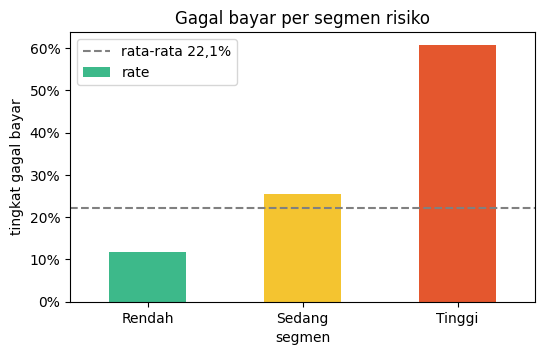

In [18]:
import matplotlib.pyplot as plt

seg = seg.loc[["Rendah", "Sedang", "Tinggi"]]
ax = seg["rate"].plot.bar(color=["#3DB98A", "#F4C430", "#E4572E"], figsize=(6, 3.5))
ax.axhline(df["default"].mean(), color="grey", linestyle="--", label="rata-rata 22,1%")
ax.set_ylabel("tingkat gagal bayar")
ax.set_title("Gagal bayar per segmen risiko")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.tick_params(axis="x", rotation=0)
ax.legend()
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

fitur = [c for c in df.columns if c not in ["default", "segmen"]]
X = df[fitur]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(23972, 26) (5993, 26)
0.22125813449023862 0.22125813449023862


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_test)

print("akurasi:", accuracy_score(y_test, pred))
print("recall:", recall_score(y_test, pred))

akurasi: 0.7787418655097614
recall: 0.0


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score

kat = ["SEX", "EDUCATION", "MARRIAGE"]
num = [c for c in fitur if c not in kat]

pre = ColumnTransformer([
    ("kat", OneHotEncoder(handle_unknown="ignore"), kat),
    ("num", StandardScaler(), num)])

lr = Pipeline([
    ("pre", pre),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
lr.fit(X_train, y_train)

p = lr.predict_proba(X_test)[:, 1]
pred = (p >= 0.5).astype(int)
print("ROC-AUC:", roc_auc_score(y_test, p))
print("recall:", recall_score(y_test, pred))
print("precision:", precision_score(y_test, pred))

ROC-AUC: 0.7545522766473372
recall: 0.6048265460030166
precision: 0.4440753045404208


[[3663 1004]
 [ 524  802]]


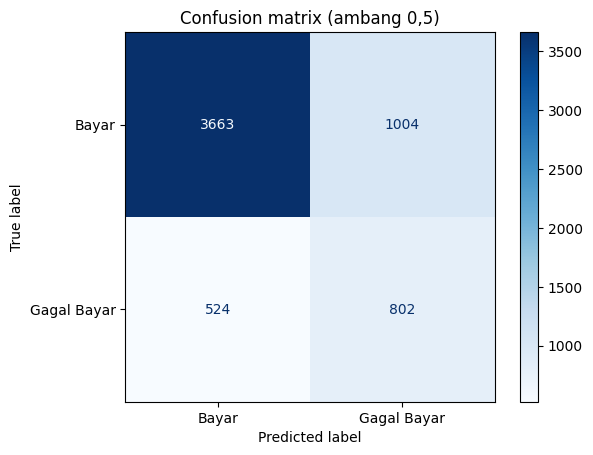

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Bayar", "Gagal Bayar"], cmap="Blues")
plt.title("Confusion matrix (ambang 0,5)")
plt.show()

In [23]:
from sklearn.ensemble import HistGradientBoostingClassifier

pre_gb = ColumnTransformer(
    [("kat", OneHotEncoder(handle_unknown="ignore"), kat)],
    remainder="passthrough")

gb = Pipeline([
    ("pre", pre_gb),
    ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=42))])
gb.fit(X_train, y_train)

p_gb = gb.predict_proba(X_test)[:, 1]
pred_gb = (p_gb >= 0.5).astype(int)
print("ROC-AUC  :", roc_auc_score(y_test, p_gb))
print("recall   :", recall_score(y_test, pred_gb))
print("precision:", precision_score(y_test, pred_gb))

ROC-AUC  : 0.7747744101019287
recall   : 0.6334841628959276
precision: 0.4547915538711424


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)
for nama, m in [("Logistic Regression", lr), ("Gradient Boosting", gb)]:
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{nama:20s} {s.mean():.3f} (+/- {s.std():.3f})")

Logistic Regression  0.760 (+/- 0.011)
Gradient Boosting    0.785 (+/- 0.006)


In [25]:
from sklearn.model_selection import RandomizedSearchCV

param = {
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [3, 4, 5, None],
    "model__max_leaf_nodes": [8, 15, 31],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 0.1, 1, 5],
    "model__max_iter": [150, 250, 400],
}
search = RandomizedSearchCV(gb, param, n_iter=15, cv=3,
                            scoring="roc_auc", random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

best = search.best_estimator_
print("Parameter terbaik:", search.best_params_)
print("ROC-AUC validasi silang terbaik:", round(search.best_score_, 3))

Parameter terbaik: {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 15, 'model__max_iter': 400, 'model__max_depth': 4, 'model__learning_rate': 0.08, 'model__l2_regularization': 1}
ROC-AUC validasi silang terbaik: 0.788


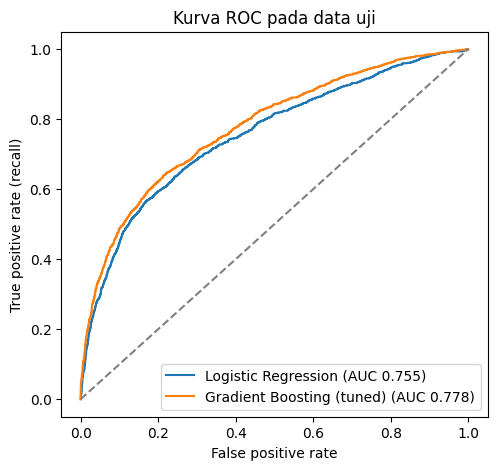

,ROC-AUC,PR-AUC,recall,precision,F1
model,,,,,
Logistic Regression,0.755,0.512,0.605,0.444,0.512
Gradient Boosting (tuned),0.778,0.561,0.642,0.457,0.534


In [26]:
from sklearn.metrics import average_precision_score, f1_score, roc_curve
import pandas as pd
import matplotlib.pyplot as plt

models = {"Logistic Regression": lr, "Gradient Boosting (tuned)": best}
rows = []
plt.figure(figsize=(5.5, 5))
for nama, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    pr = (p >= 0.5).astype(int)
    rows.append({"model": nama,
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "recall": recall_score(y_test, pr),
                 "precision": precision_score(y_test, pr),
                 "F1": f1_score(y_test, pr)})
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{nama} (AUC {rows[-1]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("Kurva ROC pada data uji")
plt.legend()
plt.show()

pd.DataFrame(rows).set_index("model").round(3)

In [27]:
import numpy as np

names = lr.named_steps["pre"].get_feature_names_out()
odds = pd.Series(np.exp(lr.named_steps["model"].coef_[0]),
                 index=[n.split("__")[1] for n in names]).sort_values()
odds.tail(10).round(2).iloc[::-1]

n_delay        2.30
max_delay      1.35
BILL_AMT2      1.33
EDUCATION_2    1.22
EDUCATION_1    1.18
PAY_1          1.17
EDUCATION_3    1.15
util_avg       1.08
BILL_AMT3      1.05
AGE            1.03
dtype: float64

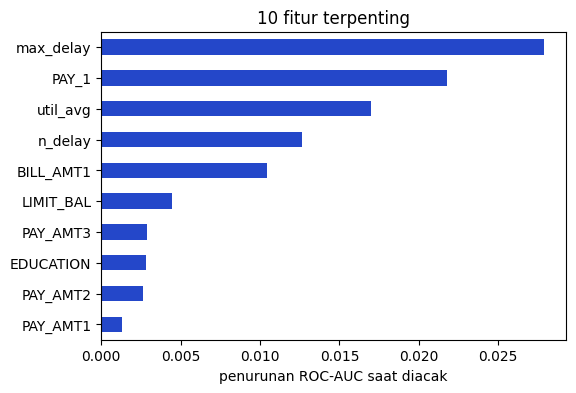

In [28]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                            n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=fitur).sort_values().tail(10)
imp.plot.barh(color="#2447C9", figsize=(6, 4))
plt.title("10 fitur terpenting")
plt.xlabel("penurunan ROC-AUC saat diacak")
plt.show()

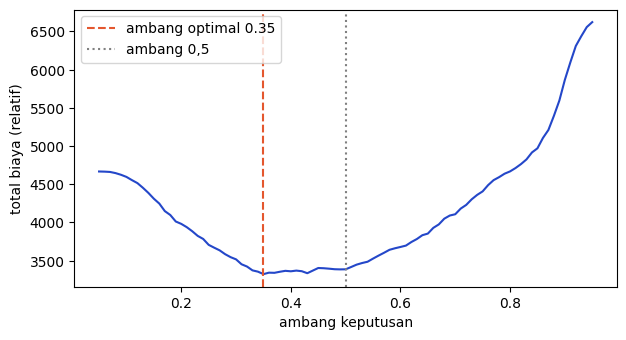

Tanpa model        : biaya 6,630
Ambang 0,5         : biaya 3,388 (lolos 475, salah tandai 1013)
Ambang optimal 0.35: biaya 3,325 (lolos 238, salah tandai 2135)
Hemat vs tanpa model: 49.8% | vs ambang 0,5: 1.9%


In [29]:
COST_FN = 5   # asumsi: satu gagal bayar yang lolos = 5 satuan kerugian
COST_FP = 1   # asumsi: satu nasabah baik yang salah ditandai = 1 satuan

p_best = best.predict_proba(X_test)[:, 1]
ths = np.linspace(0.05, 0.95, 91)

def total_cost(t):
    tandai = p_best >= t
    fn = int(((~tandai) & (y_test == 1)).sum())
    fp = int((tandai & (y_test == 0)).sum())
    return COST_FN * fn + COST_FP * fp, fn, fp

costs = np.array([total_cost(t)[0] for t in ths])
best_t = float(ths[costs.argmin()])

c_opt, fn_o, fp_o = total_cost(best_t)
c_05, fn_5, fp_5 = total_cost(0.5)
c_none = COST_FN * int(y_test.sum())   # tanpa model: semua gagal bayar lolos

plt.figure(figsize=(7, 3.6))
plt.plot(ths, costs, color="#2447C9")
plt.axvline(best_t, color="#E4572E", ls="--", label=f"ambang optimal {best_t:.2f}")
plt.axvline(0.5, color="grey", ls=":", label="ambang 0,5")
plt.xlabel("ambang keputusan"); plt.ylabel("total biaya (relatif)")
plt.legend(); plt.show()

print(f"Tanpa model        : biaya {c_none:,}")
print(f"Ambang 0,5         : biaya {c_05:,} (lolos {fn_5}, salah tandai {fp_5})")
print(f"Ambang optimal {best_t:.2f}: biaya {c_opt:,} (lolos {fn_o}, salah tandai {fp_o})")
print(f"Hemat vs tanpa model: {1 - c_opt / c_none:.1%} | vs ambang 0,5: {1 - c_opt / c_05:.1%}")

In [30]:
for fn in [2, 5, 10]:
    COST_FN = fn
    costs = np.array([total_cost(t)[0] for t in ths])
    print(f"biaya FN = {fn}x -> ambang optimal {ths[costs.argmin()]:.2f}")
COST_FN = 5   # kembalikan ke nilai awal


biaya FN = 2x -> ambang optimal 0.65
biaya FN = 5x -> ambang optimal 0.35
biaya FN = 10x -> ambang optimal 0.25


In [31]:
import joblib

joblib.dump({"model": best, "threshold": best_t, "features": fitur,
             "cost_fn": COST_FN, "cost_fp": COST_FP}, "model.joblib")
df.to_csv("data_dashboard.csv", index=False)

In [33]:
con.register("nasabah", df.rename(columns={"default": "gagal_bayar"}))

In [34]:
sql("""
SELECT CASE WHEN util_avg < 0.2 THEN '1. di bawah 20%'
            WHEN util_avg < 0.4 THEN '2. 20-40%'
            WHEN util_avg < 0.6 THEN '3. 40-60%'
            WHEN util_avg < 0.8 THEN '4. 60-80%'
            WHEN util_avg <= 1.0 THEN '5. 80-100%'
            ELSE '6. di atas 100%' END AS utilisasi_limit,
       COUNT(*) AS nasabah,
       ROUND(100.0 * AVG(gagal_bayar), 1) AS persen_gagal_bayar
FROM nasabah
GROUP BY 1
ORDER BY 1
""")

,utilisasi_limit,nasabah,persen_gagal_bayar
0,1. di bawah 20%,13453,18.0
1,2. 20-40%,3607,18.4
2,3. 40-60%,3642,23.1
3,4. 60-80%,4199,25.8
4,5. 80-100%,4427,31.6
5,6. di atas 100%,637,34.2
